# AICS-202 | Laboratory 02
## FGSM Evasion Testing in a Local Sandbox
Course module: 2 | Suggested duration: 4 hours

**Objective:** generate and measure controlled adversarial examples against a classifier you own. Only the local scikit-learn digits data are used.

**Assumption:** white-box access to the locally trained logistic regression model. Results do not generalise automatically to different architectures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


### Part A - Compute the input gradient and FGSM perturbation
Use the gradient of cross-entropy with respect to the normalised image input.

In [2]:
def input_loss_gradient(model, features, labels):
    """Cross-entropy gradient with respect to input, for multinomial logistic regression."""
    probs = model.predict_proba(features)
    targets = np.zeros_like(probs)
    label_indices = np.searchsorted(model.classes_, labels)
    targets[np.arange(len(labels)), label_indices] = 1.0
    return (probs - targets) @ model.coef_

def fgsm(model, features, labels, epsilon=0.10):
    grad = input_loss_gradient(model, features, labels)
    return np.clip(features + epsilon * np.sign(grad), 0.0, 1.0)

Epsilon=0.00 | Accuracy=0.962
Epsilon=0.03 | Accuracy=0.907
Epsilon=0.07 | Accuracy=0.791
Epsilon=0.12 | Accuracy=0.516
Epsilon=0.18 | Accuracy=0.204


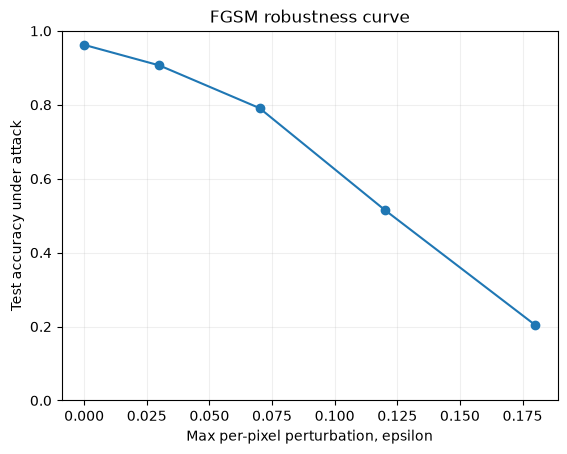

In [3]:
epsilons = [0.00, 0.03, 0.07, 0.12, 0.18]
results = []
for eps in epsilons:
    changed = fgsm(model, X_test, y_test, epsilon=eps)
    acc = accuracy_score(y_test, model.predict(changed))
    results.append((eps, acc))
    print(f'Epsilon={eps:0.2f} | Accuracy={acc:.3f}')
plt.plot([p[0] for p in results], [p[1] for p in results], marker='o')
plt.xlabel('Max per-pixel perturbation, epsilon')
plt.ylabel('Test accuracy under attack')
plt.title('FGSM robustness curve')
plt.ylim(0, 1); plt.grid(alpha=.2); plt.show()

### Part B - Display clean and adversarial samples

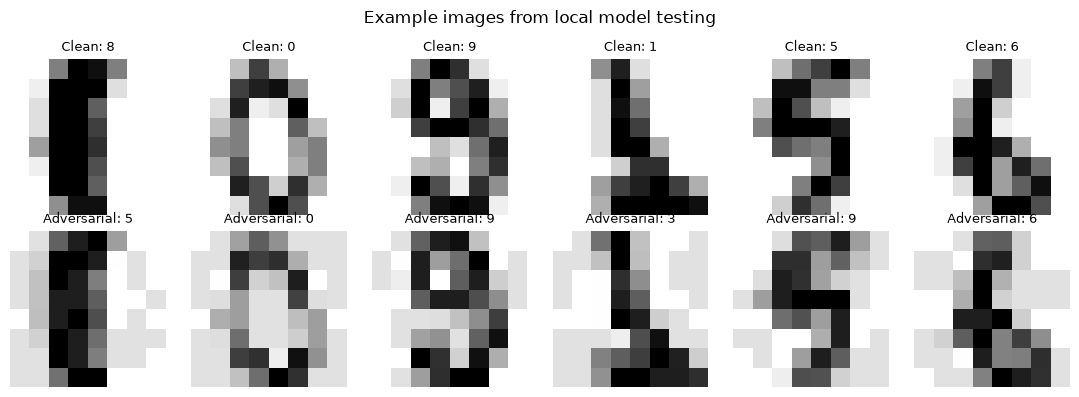

Max observed L-infinity change: 0.12


In [4]:
epsilon = 0.12
adversarial = fgsm(model, X_test, y_test, epsilon=epsilon)
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for j in range(6):
    axes[0, j].imshow(X_test[j].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[1, j].imshow(adversarial[j].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[0, j].set_title('Clean: ' + str(model.predict(X_test[j:j+1])[0]), fontsize=9)
    axes[1, j].set_title('Adversarial: ' + str(model.predict(adversarial[j:j+1])[0]), fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.suptitle('Example images from local model testing');plt.tight_layout();plt.show()
print('Max observed L-infinity change:', np.max(np.abs(adversarial-X_test)))

### Student exercises
1. Repeat the experiment using an additional epsilon of your choice between 0.01 and 0.20.
2. Report the clean accuracy, attacked accuracy, maximum perturbation, and an example prediction change.
3. Identify the limits of the experiment, including image size, model type and threat assumptions.

**Deliverables:** robustness curve, selected images, result table and a short analysis. Do not use these methods against third-party systems.

  eps     acc  drop (pp)  max change  preds changed
 0.00   0.962        0.0       0.000              0
 0.03   0.907        5.6       0.030             25
 0.07   0.791       17.1       0.070             77
 0.10   0.624       33.8       0.100            152
 0.12   0.516       44.7       0.120            202
 0.18   0.204       75.8       0.180            342


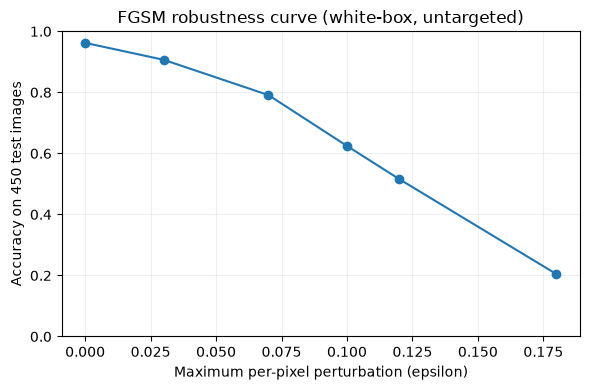

In [5]:
import os
os.makedirs('../results', exist_ok=True)

my_eps = 0.10   # your own epsilon, must be between 0.01 and 0.20
eps_list = sorted([0.00, 0.03, 0.07, 0.12, 0.18, my_eps])

clean_pred = model.predict(X_test)
clean_acc = accuracy_score(y_test, clean_pred)

table = []
print(f"{'eps':>5} {'acc':>7} {'drop (pp)':>10} {'max change':>11} {'preds changed':>14}")
for eps in eps_list:
    adv = fgsm(model, X_test, y_test, epsilon=eps)
    adv_pred = model.predict(adv)
    acc = accuracy_score(y_test, adv_pred)
    drop = (clean_acc - acc) * 100
    max_change = np.max(np.abs(adv - X_test))
    changed = int(np.sum(adv_pred != clean_pred))
    table.append((eps, acc, drop, max_change, changed))
    print(f"{eps:5.2f} {acc:7.3f} {drop:10.1f} {max_change:11.3f} {changed:14d}")

plt.figure(figsize=(6, 4))
plt.plot([r[0] for r in table], [r[1] for r in table], marker='o')
plt.xlabel('Maximum per-pixel perturbation (epsilon)')
plt.ylabel('Accuracy on 450 test images')
plt.title('FGSM robustness curve (white-box, untargeted)')
plt.ylim(0, 1); plt.grid(alpha=.2); plt.tight_layout()
plt.savefig('../results/E02_fgsm_curve.png', dpi=200)
plt.show()

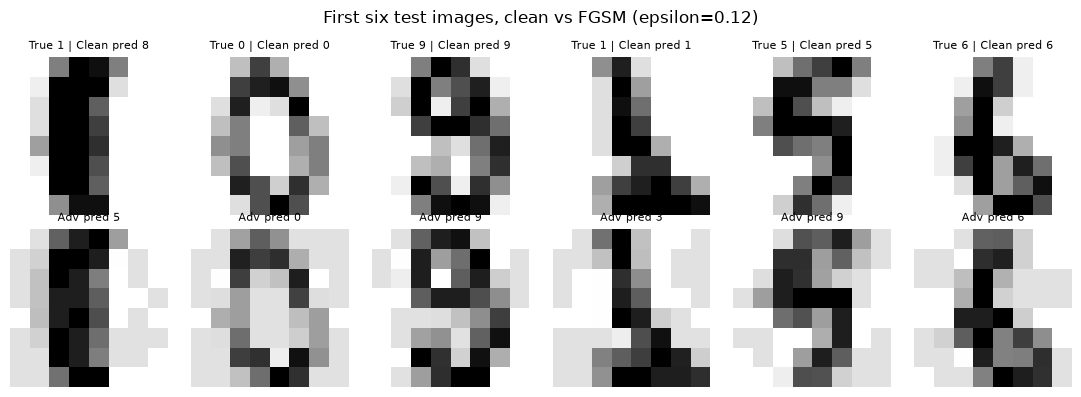

Max observed L-infinity change: 0.12


In [6]:
eps = 0.12
adv = fgsm(model, X_test, y_test, epsilon=eps)
adv_pred = model.predict(adv)

fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for j in range(6):
    axes[0, j].imshow(X_test[j].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[1, j].imshow(adv[j].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[0, j].set_title(f'True {y_test[j]} | Clean pred {clean_pred[j]}', fontsize=8)
    axes[1, j].set_title(f'Adv pred {adv_pred[j]}', fontsize=8)
for ax in axes.ravel(): ax.axis('off')
plt.suptitle(f'First six test images, clean vs FGSM (epsilon={eps})')
plt.tight_layout()
plt.savefig('../results/E02_image_pairs.png', dpi=200)
plt.show()
print('Max observed L-infinity change:', np.max(np.abs(adv - X_test)))

In [7]:
flipped = np.where((clean_pred == y_test) & (adv_pred != y_test))[0]
print('Correct on clean, wrong under attack:', len(flipped), 'images')
print('First indices:', flipped[:10])

i = int(flipped[0])
p_clean = model.predict_proba(X_test[i:i+1])[0]
p_adv = model.predict_proba(adv[i:i+1])[0]
print(f'Index {i}: true {y_test[i]}, clean pred {clean_pred[i]} (conf {p_clean.max():.3f}), '
      f'adv pred {adv_pred[i]} (conf {p_adv.max():.3f})')
print('Pixels changed:', int(np.sum(np.abs(adv[i] - X_test[i]) > 1e-12)), 'of 64')

Correct on clean, wrong under attack: 201 images
First indices: [ 3  4  6  7 10 13 14 18 28 30]
Index 3: true 1, clean pred 1 (conf 0.927), adv pred 3 (conf 0.550)
Pixels changed: 47 of 64


In [8]:
diff = np.abs(adv - X_test)
print('Share of pixel values changed by less than eps:', round(float(np.mean(diff < eps - 1e-9)), 3))
print('Share of clean pixels exactly 0:', round(float(np.mean(X_test == 0)), 3))

Share of pixel values changed by less than eps: 0.29
Share of clean pixels exactly 0: 0.491
